# Notebook 03 — Feature Engineering
Credit Risk Scoring & Default Prediction

## Objetivo
Crear predictores a partir de seis meses de historial y separar entrenamiento y prueba antes de ajustar transformaciones. No entrenaremos ni seleccionaremos modelos todavía. Fuente: [UCI, dataset 350](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients). El horizonte es el siguiente mes; no es una PD anual ni una muestra mexicana.

## 1. Configuración
Ejecuta desde la carpeta del proyecto o notebooks. Si faltan dependencias: `%pip install pandas numpy matplotlib scikit-learn ucimlrepo`.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from IPython.display import display
RANDOM_STATE = 42
TARGET = "DEFAULT"
root = Path.cwd()
if root.name.lower() == "notebooks":
    root = root.parent
processed = root / "data" / "processed"
processed.mkdir(parents=True, exist_ok=True)
print(root)

C:\Users\pirom\OneDrive\Documentos\Proyectos\credit_risk_scoring


## 2. Cargar y normalizar el esquema
Buscamos primero el resultado del Notebook 01. Si no existe, usamos el CSV crudo o UCI. Reconocemos los nombres X1–X23 y ambos nombres del target.

In [2]:
source = processed / "credit_risk_eda_base.csv"
raw = root / "data" / "raw" / "default_credit_clients.csv"
if source.exists():
    df = pd.read_csv(source)
elif raw.exists():
    df = pd.read_csv(raw)
else:
    from ucimlrepo import fetch_ucirepo
    dataset = fetch_ucirepo(id=350)
    df = pd.concat([dataset.data.features, dataset.data.targets], axis=1)
status = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
bills = [f"BILL_AMT{i}" for i in range(1, 7)]
pays = [f"PAY_AMT{i}" for i in range(1, 7)]
original = ["LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE"] + status + bills + pays
mapping = {f"X{i}": name for i, name in enumerate(original, 1)}
mapping["DEFAULT.PAYMENT.NEXT.MONTH"] = TARGET
mapping["Y"] = TARGET
df.columns = df.columns.astype(str).str.strip().str.upper()
df = df.rename(columns=mapping)
assert df.columns.is_unique, "Columnas duplicadas después de renombrar"
missing = set(original + [TARGET]) - set(df.columns)
assert not missing, f"Faltan columnas: {missing}"
df = df[original + [TARGET]].apply(pd.to_numeric, errors="raise")
assert df[TARGET].isin([0, 1]).all(), "Target inválido o faltante"
print(df.shape)
display(df.head(3))

(30000, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0


## 3. Separación estratificada
Reservamos 20% como prueba final. El 80% restante se usará en validación cruzada en el Notebook 04. El dataset es una fotografía histórica transversal: no permite validar fuera del tiempo. El EDA previo observó todos los registros, por lo que esta prueba no representa una validación externa completamente independiente.

In [3]:
train, test = train_test_split(df, test_size=0.20, random_state=RANDOM_STATE, stratify=df[TARGET])
assert train.index.intersection(test.index).empty
assert len(train) + len(test) == len(df)
summary = pd.DataFrame({"filas": [len(train), len(test)], "default_pct": [train[TARGET].mean()*100, test[TARGET].mean()*100]}, index=["train", "test"])
display(summary.round(2))

,filas,default_pct
train,24000,22.12
test,6000,22.12


## 4. Ingeniería de características
Todas las operaciones usan únicamente información de cada cliente disponible antes del objetivo. Los códigos positivos indican atraso; los códigos negativos o cero se conservan y no se cuentan como atrasos. Los saldos negativos se conservan; para ratios de deuda se usa la parte positiva. Si un denominador no es positivo, el ratio queda como NaN, no cero. Los agregados conservan faltantes cuando no existe información suficiente.

In [4]:
def safe_ratio(numerator, denominator):
    return numerator.div(denominator.where(denominator > 0))

def engineer(frame):
    out = frame.copy()
    s, b, p = out[status], out[bills], out[pays]
    out["late_months"] = s.gt(0).sum(axis=1).where(s.notna().all(axis=1))
    out["late_2plus_months"] = s.ge(2).sum(axis=1).where(s.notna().all(axis=1))
    out["max_delay"] = s.clip(lower=0).max(axis=1)
    out["delay_change"] = s.iloc[:, 0].clip(lower=0) - s.iloc[:, -1].clip(lower=0)
    out["bill_mean"] = b.mean(axis=1)
    out["bill_std"] = b.std(axis=1, ddof=0)
    out["bill_change"] = b.iloc[:, 0] - b.iloc[:, -1]
    out["payment_mean"] = p.mean(axis=1)
    out["payment_std"] = p.std(axis=1, ddof=0)
    out["zero_payment_months"] = p.eq(0).sum(axis=1).where(p.notna().all(axis=1))
    out["utilization_recent"] = safe_ratio(b.iloc[:, 0].clip(lower=0), out["LIMIT_BAL"])
    out["utilization_mean"] = safe_ratio(b.clip(lower=0).mean(axis=1), out["LIMIT_BAL"])
    out["payment_to_limit"] = safe_ratio(p.mean(axis=1), out["LIMIT_BAL"])
    # Pago de septiembre frente a factura de agosto: aproximación, no conciliación contable.
    out["payment_to_previous_bill"] = safe_ratio(p.iloc[:, 0], b.iloc[:, 1])
    out["previous_bill_nonpositive"] = b.iloc[:, 1].le(0).astype(float).where(b.iloc[:, 1].notna())
    return out.replace([np.inf, -np.inf], np.nan)

train_fe = engineer(train.drop(columns=TARGET))
test_fe = engineer(test.drop(columns=TARGET))
new_cols = [col for col in train_fe if col not in original]
assert list(train_fe.columns) == list(test_fe.columns)
assert TARGET not in train_fe
print("Nuevas variables:", len(new_cols))
display(train_fe[new_cols].head())

Nuevas variables: 15


,late_months,late_2plus_months,max_delay,delay_change,bill_mean,bill_std,bill_change,payment_mean,payment_std,zero_payment_months,utilization_recent,utilization_mean,payment_to_limit,payment_to_previous_bill,previous_bill_nonpositive
22788,4,4,3,2,165490.000000,3864.492895,-1234,6583.333333,5637.202813,2,1.011069,1.034312,0.041146,0.086890,0.0
29006,1,0,1,1,8.833333,19.751934,0,8.833333,19.751934,5,0.000000,0.000059,0.000059,1.000000,0.0
16950,2,1,2,1,8576.833333,725.058024,1771,669.333333,486.199433,0,1.017100,0.857683,0.066933,0.000245,0.0
22280,0,0,0,0,186262.333333,37836.311711,72533,6947.833333,1799.557392,0,0.940359,0.846647,0.031581,0.043120,0.0
11346,1,0,1,1,30.333333,230.029467,235,254.333333,439.348634,4,0.000000,0.000351,0.000820,NaN,1.0


## 5. Revisar calidad de las nuevas variables
El diagnóstico se limita al entrenamiento. No descartamos variables por los valores observados en prueba. En el próximo notebook imputaremos y escalaremos dentro de un Pipeline ajustado en cada fold.

In [5]:
audit = pd.DataFrame({"missing_pct": train_fe[new_cols].isna().mean()*100, "min": train_fe[new_cols].min(), "median": train_fe[new_cols].median(), "max": train_fe[new_cols].max()})
display(audit.round(3))
assert not np.isinf(train_fe.to_numpy()).any()
assert train_fe["late_months"].dropna().between(0, 6).all()
assert train_fe["late_2plus_months"].dropna().between(0, 6).all()

,missing_pct,min,median,max
late_months,0.00,0.000,0.000,6.000
late_2plus_months,0.00,0.000,0.000,6.000
max_delay,0.00,0.000,0.000,8.000
delay_change,0.00,-6.000,0.000,6.000
bill_mean,0.00,-56043.167,21044.833,877313.833
bill_std,0.00,0.000,4188.089,308946.172
bill_change,0.00,-399983.000,927.500,708323.000
payment_mean,0.00,0.000,2405.667,627344.333
payment_std,0.00,0.000,1304.373,423588.013
zero_payment_months,0.00,0.000,0.000,6.000


## 6. Explorar los predictores en entrenamiento
La tasa por número de meses con atraso es descriptiva, no causal. Los grupos pequeños pueden ser inestables.

In [6]:
analysis = train_fe.assign(DEFAULT=train[TARGET])
risk = analysis.groupby("late_months")[TARGET].agg(clientes="size", tasa="mean")
display(risk.assign(tasa_pct=risk.tasa*100).round(3))
ax = (risk.tasa*100).plot.bar(figsize=(8,4), color="steelblue")
ax.set(title="Incumplimiento según meses con atraso (train)", xlabel="Meses con atraso", ylabel="Tasa de incumplimiento (%)")
plt.tight_layout(); plt.show()

,clientes,tasa,tasa_pct
late_months,,,
0,15896,0.115,11.512
1,3572,0.300,29.955
2,1532,0.399,39.948
3,936,0.503,50.321
4,767,0.580,58.018
5,237,0.599,59.916
6,1060,0.697,69.717


<Figure size 800x400 with 1 Axes>

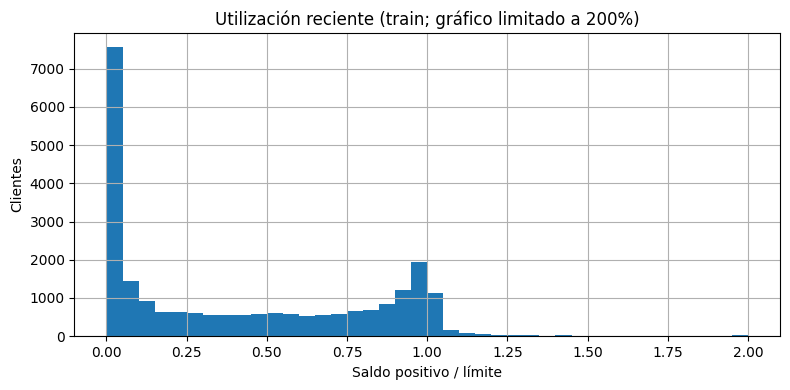

In [7]:
ax = train_fe["utilization_recent"].dropna().clip(upper=2).hist(bins=40, figsize=(8,4))
ax.set(title="Utilización reciente (train; gráfico limitado a 200%)", xlabel="Saldo positivo / límite", ylabel="Clientes")
plt.tight_layout(); plt.show()

## 7. Política de variables y exportación
Por decisión conservadora del proyecto, excluimos SEX, AGE, EDUCATION y MARRIAGE de los predictores del modelo base; se conservan por separado para auditorías de equidad. Esta exclusión no garantiza ausencia de sesgo. No aplicamos SMOTE, escalado ni imputación a todo el dataset. Tampoco seleccionamos variables usando test.

In [8]:
audit_cols = ["SEX", "AGE", "EDUCATION", "MARRIAGE"]
X_train = train_fe.drop(columns=audit_cols)
X_test = test_fe.drop(columns=audit_cols)
y_train = train[TARGET].astype(int)
y_test = test[TARGET].astype(int)
assert list(X_train.columns) == list(X_test.columns)
assert TARGET not in X_train
for name, X, y, demographics in [("train", X_train, y_train, train[audit_cols]), ("test", X_test, y_test, test[audit_cols])]:
    X.assign(DEFAULT=y).to_csv(processed / f"credit_risk_{name}_features.csv", index_label="row_id")
    demographics.to_csv(processed / f"credit_risk_{name}_audit.csv", index_label="row_id")
manifest = {"target": TARGET, "random_state": RANDOM_STATE, "test_size": 0.2, "features": list(X_train.columns), "audit_only": audit_cols, "new_features": new_cols}
(processed / "feature_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Archivos guardados en", processed)

Train: (24000, 34) Test: (6000, 34)
Archivos guardados en C:\Users\pirom\OneDrive\Documentos\Proyectos\credit_risk_scoring\data\processed


## 8. Siguiente paso
Notebook 04: DummyClassifier como referencia, regresión logística y modelos de árboles. Ajustar medianas, escalado y cualquier remuestreo dentro de validación cruzada sobre train. Mantener test reservado para evaluación final. Revisar calibración, PR-AUC, ROC-AUC, KS y costos. Al ejecutar este cuaderno, interpreta los resultados reales sin asumir que las variables nuevas mejoran la predicción.